# Credit Risk Monitoring and MI Pack

Portfolio credit-risk monitoring on real loans: vintage cohort performance, live-book delinquency, scorecard drift (PSI), concentration, and a RAG early-warning dashboard. This notebook runs the full pipeline and embeds the results and figures.

**Data:** the Lending Club loan tape (publicly available). See `MI_PACK.md` for the committee-ready summary and `results.json` for all metrics.

In [1]:
import warnings; warnings.filterwarnings("ignore")
import numpy as np, pandas as pd, json, os
import matplotlib; matplotlib.use("Agg")
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter
from matplotlib.patches import Rectangle
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

RAW="/mnt/user-data/uploads/accepted_2007_to_2018Q4_csv.gz"
PARQUET="/home/claude/fin2/data/lending_affordability.parquet"
OUT="/home/claude/monitoring"; FIG=f"{OUT}/figures"; DAT=f"{OUT}/data"
os.makedirs(FIG,exist_ok=True); os.makedirs(DAT,exist_ok=True)
NAVY="#16314E"; TEAL="#1C8C7D"; AMBER="#C8862B"; RED="#B23A48"; SLATE="#5B6B7B"; GREEN="#2E7D5B"; GREY="#9AA7B5"
RAGC={"GREEN":"#2E7D5B","AMBER":"#C8862B","RED":"#B23A48"}
plt.rcParams.update({"font.family":"DejaVu Sans","axes.edgecolor":GREY,"axes.linewidth":0.8,"axes.grid":True,
    "grid.color":"#E6ECF2","grid.linewidth":0.7,"axes.axisbelow":True,"figure.dpi":120})
usd=lambda x,_=None: f"${x/1e9:,.1f}bn" if abs(x)>=1e9 else (f"${x/1e6:,.0f}m" if abs(x)>=1e6 else f"${x/1e3:,.0f}k")
MON={m:i+1 for i,m in enumerate(['Jan','Feb','Mar','Apr','May','Jun','Jul','Aug','Sep','Oct','Nov','Dec'])}
def ym(s):
    try: p=str(s).split('-'); return int(p[1])*12+MON.get(p[0],0)
    except: return np.nan

CHARGED={'Charged Off','Default','Does not meet the credit policy. Status:Charged Off'}
ACTIVE={'Current','In Grace Period','Late (16-30 days)','Late (31-120 days)','Default'}
USE=['issue_d','last_pymnt_d','loan_status','loan_amnt','funded_amnt','out_prncp','total_rec_prncp',
     'grade','sub_grade','addr_state','purpose','term','fico_range_low','fico_range_high']
print("Reading loan tape ...")
rows=[]
for ch in pd.read_csv(RAW,usecols=USE,chunksize=300000,low_memory=False):
    ch['issue_m']=ch['issue_d'].map(ym); ch['last_m']=ch['last_pymnt_d'].map(ym)
    ch['issue_year']=(ch['issue_m']//12).astype('float')
    ch['default']=ch['loan_status'].isin(CHARGED).astype(int)
    ch['mob_default']=np.where(ch['default']==1, ch['last_m']-ch['issue_m'], np.nan)
    ch['active']=ch['loan_status'].isin(ACTIVE) & (ch['out_prncp']>0)
    ch['fico']=(ch['fico_range_low']+ch['fico_range_high'])/2
    rows.append(ch[['issue_year','mob_default','default','active','loan_status','out_prncp','funded_amnt',
                    'loan_amnt','grade','sub_grade','addr_state','purpose','term','fico']])
df=pd.concat(rows,ignore_index=True); del rows
df['term_months']=df['term'].astype(str).str.extract(r'(\d+)').astype(float)
print(f"  {len(df):,} loans | overall default {df['default'].mean():.3f}")

Reading loan tape ...


  2,260,701 loans | overall default 0.119


### =

In [2]:
# 1) VINTAGE COHORT PERFORMANCE

### =

In [3]:
ttc=df['default'].mean()
vint_years=list(range(2012,2018))
# cumulative default by months-on-book per cohort
MOBS=np.arange(0,25)
curves={}
for v in [2012,2013,2014,2015,2016]:
    coh=df[df['issue_year']==v]; n=len(coh)
    md=coh['mob_default'].dropna()
    curves[v]=[ (md<=m).sum()/n*100 for m in MOBS ]
# 12-month-on-book default rate by vintage (apples-to-apples early indicator)
dr12={}
for v in vint_years:
    coh=df[df['issue_year']==v]; n=len(coh)
    dr12[v]=float(((coh['mob_default']<=12).sum())/n*100)
print("12-month-on-book default by vintage:",{k:round(v,2) for k,v in dr12.items()})

12-month-on-book default by vintage: {2012: 5.59, 2013: 4.71, 2014: 5.18, 2015: 5.93, 2016: 6.76, 2017: 6.28}


### =

In [4]:
# 2) LIVE-BOOK DELINQUENCY PROFILE

### =

In [5]:
act=df[df['active']].copy()
BUCKETS=['Current','In Grace Period','Late (16-30 days)','Late (31-120 days)','Default']
lab={'Current':'Current','In Grace Period':'Grace','Late (16-30 days)':'1-29 dpd',
     'Late (31-120 days)':'30-119 dpd','Default':'Default'}
ead_by=act.groupby('loan_status')['out_prncp'].sum().reindex(BUCKETS).fillna(0)
tot_ead=act['out_prncp'].sum()
deelinq_ead=ead_by[['Late (16-30 days)','Late (31-120 days)','Default']].sum()
delinq_rate=float(deelinq_ead/tot_ead*100)
impaired_ead=ead_by[['Late (31-120 days)','Default']].sum()
impaired_share=float(impaired_ead/tot_ead*100)
print(f"Live book: active EAD ${tot_ead/1e9:.2f}bn | delinquency rate {delinq_rate:.2f}% | impaired share {impaired_share:.2f}%")

Live book: active EAD $9.51bn | delinquency rate 3.08% | impaired share 2.57%


### =

In [6]:
# 3) SCORECARD DRIFT  (PSI of PD score by vintage vs baseline)

### =

In [7]:
pf=pd.read_parquet(PARQUET)
NUM=['fico','dti_eff','payment_to_income','loan_to_income','annual_inc_eff','term_months','revol_util',
     'delinq_2yrs','inq_last_6mths','open_acc','total_acc','credit_history_yrs']
for c in NUM: pf[c]=pd.to_numeric(pf[c],errors='coerce')
pf=pf.dropna(subset=['issue_year'])
tr=pf[pf['issue_year']<=2014]
pdm=Pipeline([("s",StandardScaler()),("lr",LogisticRegression(max_iter=1000))])
Xtr=tr[NUM].fillna(tr[NUM].median()); pdm.fit(Xtr,tr['default'])
pf['pd']=pdm.predict_proba(pf[NUM].fillna(tr[NUM].median()))[:,1]
base=pf[pf['issue_year'].isin([2013,2014])]['pd']
edges=np.quantile(base,np.linspace(0,1,11)); edges[0],edges[-1]=-np.inf,np.inf
base_d=pd.cut(base,edges).value_counts(normalize=True).sort_index()
psi_by={}
for v in range(2013,2019):
    s=pf[pf['issue_year']==v]['pd']
    if len(s)<500: continue
    d=pd.cut(s,edges).value_counts(normalize=True).sort_index()
    psi_by[v]=float((((base_d-d)*np.log((base_d+1e-6)/(d+1e-6)))).sum())
print("Scorecard PSI by vintage (vs 2013-14):",{k:round(v,3) for k,v in psi_by.items()})

Scorecard PSI by vintage (vs 2013-14): {2013: 0.001, 2014: 0.0, 2015: 0.006, 2016: 0.023, 2017: 0.041, 2018: 0.132}


### =

In [8]:
# 4) PORTFOLIO CONCENTRATION  (HHI + top exposures)

### =

In [9]:
def hhi(shares): return float((shares**2).sum())
st=act.groupby('addr_state')['out_prncp'].sum().sort_values(ascending=False)
st_share=st/st.sum(); hhi_state=hhi(st_share); top5_state=float(st_share.head(5).sum()*100)
gr=act.groupby('grade')['out_prncp'].sum().sort_values(ascending=False); gr_share=gr/gr.sum(); hhi_grade=hhi(gr_share)
pu=act.groupby('purpose')['out_prncp'].sum().sort_values(ascending=False); pu_share=pu/pu.sum(); top_purpose=float(pu_share.head(1).sum()*100)
print(f"Concentration: state HHI {hhi_state:.3f} (top5 {top5_state:.1f}%) | grade HHI {hhi_grade:.3f} | largest purpose {top_purpose:.1f}%")

Concentration: state HHI 0.051 (top5 41.3%) | grade HHI 0.236 | largest purpose 58.4%


### =

In [10]:
# 5) EARLY-WARNING INDICATORS  (RAG)

### =

In [11]:
def rag(v,g,a,higher_bad=True):
    if higher_bad: return "GREEN" if v<g else ("AMBER" if v<a else "RED")
    return "GREEN" if v>g else ("AMBER" if v>a else "RED")
mature=[v for v in dr12 if v<=2016]
dr12_latest=dr12[max(mature)]; dr12_ratio=dr12_latest/ (np.mean([dr12[v] for v in mature[:2]]) )
psi_latest=psi_by[max(psi_by)]
EWI=[
 ("Vintage 12m default trend", f"{dr12_latest:.1f}% (latest mature vintage)", rag(dr12_ratio,1.10,1.25)),
 ("Live-book delinquency rate", f"{delinq_rate:.1f}% of active EAD", rag(delinq_rate,4.0,7.0)),
 ("Impaired (30+ dpd) share",   f"{impaired_share:.1f}% of active EAD", rag(impaired_share,3.0,6.0)),
 ("Scorecard population drift (PSI)", f"{psi_latest:.3f} vs baseline", rag(psi_latest,0.10,0.25)),
 ("Geographic concentration (HHI)", f"{hhi_state:.3f} (top-5 states {top5_state:.0f}%)", rag(hhi_state,0.10,0.18)),
 ("Product concentration (largest purpose)", f"{top_purpose:.0f}% of EAD", rag(top_purpose/100,0.45,0.60)),
]
for n,v,r in EWI: print(f"  [{r:5s}] {n}: {v}")

  [RED  ] Vintage 12m default trend: 6.8% (latest mature vintage)
  [GREEN] Live-book delinquency rate: 3.1% of active EAD
  [GREEN] Impaired (30+ dpd) share: 2.6% of active EAD
  [AMBER] Scorecard population drift (PSI): 0.132 vs baseline
  [GREEN] Geographic concentration (HHI): 0.051 (top-5 states 41%)
  [AMBER] Product concentration (largest purpose): 58% of EAD


### =

In [12]:
# FIGURES

### =

In [13]:
# F1 vintage cohort curves
fig,ax=plt.subplots(figsize=(8.8,4.8))
cmap=[NAVY,TEAL,GREEN,AMBER,RED]
for (v,c),col in zip(curves.items(),cmap): ax.plot(MOBS,c,lw=2,color=col,label=str(v))
ax.set_xlabel("Months on book"); ax.set_ylabel("Cumulative default rate (%)")
ax.set_title("Vintage cohort performance: cumulative default by months on book")
ax.legend(title="Vintage",frameon=False,ncol=5,loc="upper left")
plt.tight_layout(); plt.savefig(f"{FIG}/01_vintage_curves.png",bbox_inches="tight"); plt.close()

# F2 12-month default by vintage
fig,ax=plt.subplots(figsize=(8.6,4.5))
ks=list(dr12.keys()); vs=[dr12[k] for k in ks]
bars=ax.bar([str(k) for k in ks],vs,color=NAVY,edgecolor="white")
bars[-1].set_color(GREY)  # latest vintage partly censored
ax.axhline(np.mean(vs[:3]),color=AMBER,ls='--',lw=1.4,label="early-vintage average")
for i,v in enumerate(vs): ax.text(i,v,f"{v:.1f}",ha="center",va="bottom",fontsize=8.5)
ax.set_ylabel("Default within 12 months on book (%)")
ax.set_title("Early-warning: 12-month-on-book default rate by vintage")
ax.legend(frameon=False); plt.tight_layout(); plt.savefig(f"{FIG}/02_vintage_12mob.png",bbox_inches="tight"); plt.close()

# F3 delinquency profile
fig,ax=plt.subplots(figsize=(8.6,4.5))
vals=[ead_by[b] for b in BUCKETS]; cols=[GREEN,"#8FB99B",AMBER,"#C8862B",RED]
ax.bar([lab[b] for b in BUCKETS],vals,color=cols,edgecolor="white")
ax.yaxis.set_major_formatter(FuncFormatter(usd))
ax.set_title(f"Live-book delinquency profile (active EAD ${tot_ead/1e9:.1f}bn, delinquency {delinq_rate:.1f}%)")
plt.tight_layout(); plt.savefig(f"{FIG}/03_delinquency_profile.png",bbox_inches="tight"); plt.close()

# F4 PSI drift
fig,ax=plt.subplots(figsize=(8.6,4.5))
ks=list(psi_by.keys()); vs=[psi_by[k] for k in ks]
ax.plot([str(k) for k in ks],vs,'o-',color=NAVY,lw=2)
ax.axhline(0.10,color=AMBER,ls='--',lw=1.3,label="0.10 moderate shift")
ax.axhline(0.25,color=RED,ls='--',lw=1.3,label="0.25 significant shift")
ax.set_ylabel("PSI vs 2013-14 baseline"); ax.set_title("Scorecard population drift over time (PSI)")
ax.set_ylim(0,max(0.3,max(vs)*1.2)); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/04_psi_drift.png",bbox_inches="tight"); plt.close()

# F5 concentration by state
fig,ax=plt.subplots(figsize=(9,4.6)); top=st_share.head(10)*100
ax.bar(top.index,top.values,color=NAVY,edgecolor="white")
ax2=ax.twinx(); ax2.plot(range(len(top)),np.cumsum(top.values),'o-',color=AMBER,lw=2,label="cumulative")
ax.set_ylabel("Share of active EAD (%)"); ax2.set_ylabel("Cumulative (%)",color=AMBER)
ax.set_title(f"Geographic concentration: top-10 states (HHI {hhi_state:.3f}, well-diversified)")
plt.tight_layout(); plt.savefig(f"{FIG}/05_concentration_state.png",bbox_inches="tight"); plt.close()

# F6 early-warning RAG dashboard
fig,ax=plt.subplots(figsize=(9.4,4.4)); ax.axis('off')
ax.set_xlim(0,10); ax.set_ylim(0,len(EWI)+1)
ax.text(0.1,len(EWI)+0.4,"Early-warning indicators",fontsize=13,fontweight='bold',color=NAVY)
for i,(name,val,r) in enumerate(EWI):
    y=len(EWI)-1-i
    ax.add_patch(Rectangle((0.1,y+0.1),9.8,0.8,facecolor="#F4F7FA",edgecolor="#E0E6EC"))
    ax.text(0.3,y+0.5,name,va='center',fontsize=10.5,color=NAVY)
    ax.text(6.3,y+0.5,val,va='center',fontsize=10,color=SLATE)
    ax.add_patch(Rectangle((9.25,y+0.25),0.5,0.5,facecolor=RAGC[r],edgecolor="white"))
plt.tight_layout(); plt.savefig(f"{FIG}/06_ewi_dashboard.png",bbox_inches="tight",dpi=130); plt.close()

# F7 score-band default: early vs recent vintages (quality drift)
pf['band']=pd.qcut(pf['pd'],8,duplicates='drop',labels=False)
early=pf[pf['issue_year'].isin([2013,2014])].groupby('band')['default'].mean()*100
recent=pf[pf['issue_year'].isin([2016,2017])].groupby('band')['default'].mean()*100
fig,ax=plt.subplots(figsize=(8.6,4.5)); x=np.arange(len(early)); w=0.4
ax.bar(x-w/2,early.values,w,label="2013-14 vintages",color=NAVY,edgecolor="white")
ax.bar(x+w/2,recent.reindex(early.index).values,w,label="2016-17 vintages",color=AMBER,edgecolor="white")
ax.set_xticks(x); ax.set_xticklabels([f"D{i+1}" for i in x],fontsize=8.5)
ax.set_xlabel("PD decile (low to high risk)"); ax.set_ylabel("Default rate (%)")
ax.set_title("Default rate by risk band: early vs recent vintages"); ax.legend(frameon=False)
plt.tight_layout(); plt.savefig(f"{FIG}/07_band_trend.png",bbox_inches="tight"); plt.close()

### =

In [14]:
S=dict(
 n_loans=int(len(df)),ttc_default=round(float(ttc),4),
 active_loans=int(len(act)),active_ead=round(float(tot_ead),0),
 delinquency_rate=round(delinq_rate,2),impaired_share=round(impaired_share,2),
 dr12_by_vintage={int(k):round(v,2) for k,v in dr12.items()},
 psi_by_vintage={int(k):round(v,3) for k,v in psi_by.items()},
 hhi_state=round(hhi_state,3),top5_state_pct=round(top5_state,1),hhi_grade=round(hhi_grade,3),
 largest_purpose_pct=round(top_purpose,1),
 ewi=[{"indicator":n,"value":v,"rag":r} for n,v,r in EWI])
json.dump(S,open(f"{OUT}/results.json","w"),indent=2)
pd.DataFrame({'state':st.index,'active_ead':st.values,'share_pct':(st_share.values*100).round(2)}).to_csv(f"{DAT}/exposure_by_state.csv",index=False)
print("\n=== SUMMARY ==="); print(json.dumps(S,indent=2)); print("DONE")


=== SUMMARY ===
{
  "n_loans": 2260701,
  "ttc_default": 0.1191,
  "active_loans": 907904,
  "active_ead": 9510384856.0,
  "delinquency_rate": 3.08,
  "impaired_share": 2.57,
  "dr12_by_vintage": {
    "2012": 5.59,
    "2013": 4.71,
    "2014": 5.18,
    "2015": 5.93,
    "2016": 6.76,
    "2017": 6.28
  },
  "psi_by_vintage": {
    "2013": 0.001,
    "2014": 0.0,
    "2015": 0.006,
    "2016": 0.023,
    "2017": 0.041,
    "2018": 0.132
  },
  "hhi_state": 0.051,
  "top5_state_pct": 41.3,
  "hhi_grade": 0.236,
  "largest_purpose_pct": 58.4,
  "ewi": [
    {
      "indicator": "Vintage 12m default trend",
      "value": "6.8% (latest mature vintage)",
      "rag": "RED"
    },
    {
      "indicator": "Live-book delinquency rate",
      "value": "3.1% of active EAD",
      "rag": "GREEN"
    },
    {
      "indicator": "Impaired (30+ dpd) share",
      "value": "2.6% of active EAD",
      "rag": "GREEN"
    },
    {
      "indicator": "Scorecard population drift (PSI)",
      "value"

## Figures

**Vintage cohort performance: cumulative default by months on book**

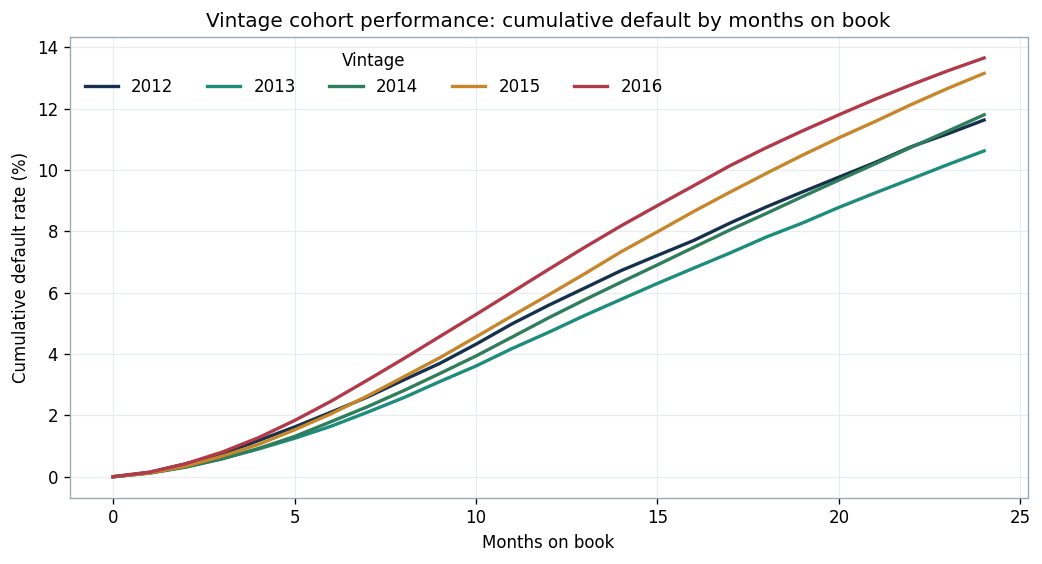

In [15]:
from IPython.display import Image
Image(filename="figures/01_vintage_curves.png")

**Early-warning: 12-month default rate by vintage**

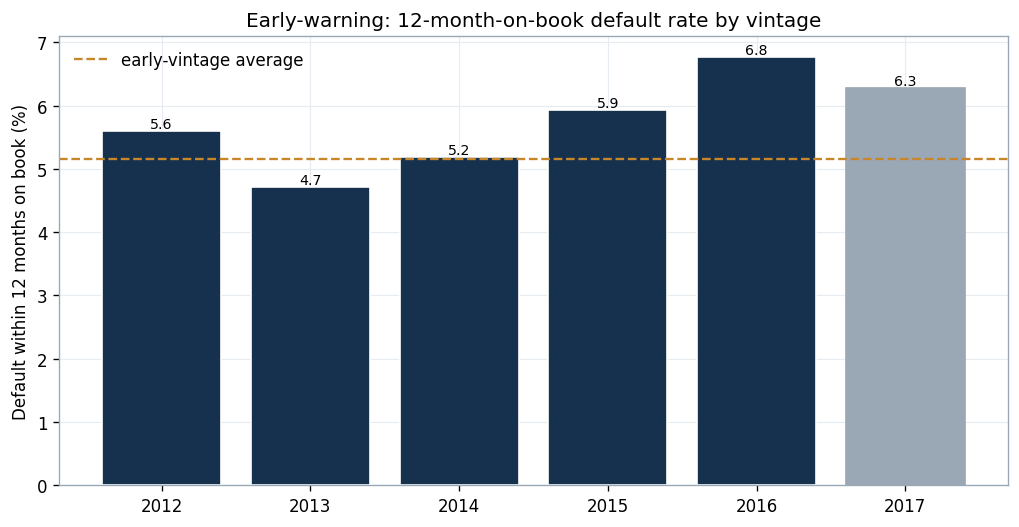

In [16]:
from IPython.display import Image
Image(filename="figures/02_vintage_12mob.png")

**Live-book delinquency profile**

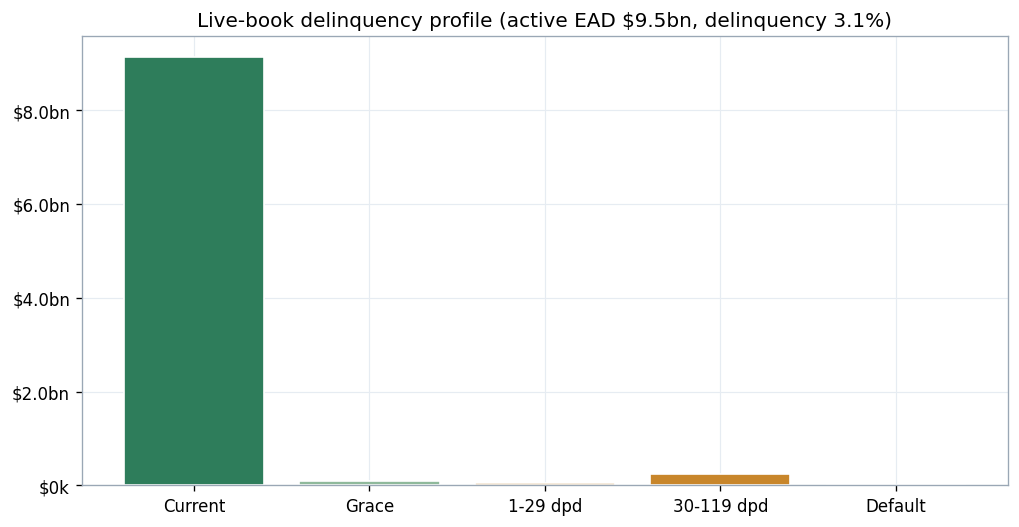

In [17]:
from IPython.display import Image
Image(filename="figures/03_delinquency_profile.png")

**Scorecard population drift over time (PSI)**

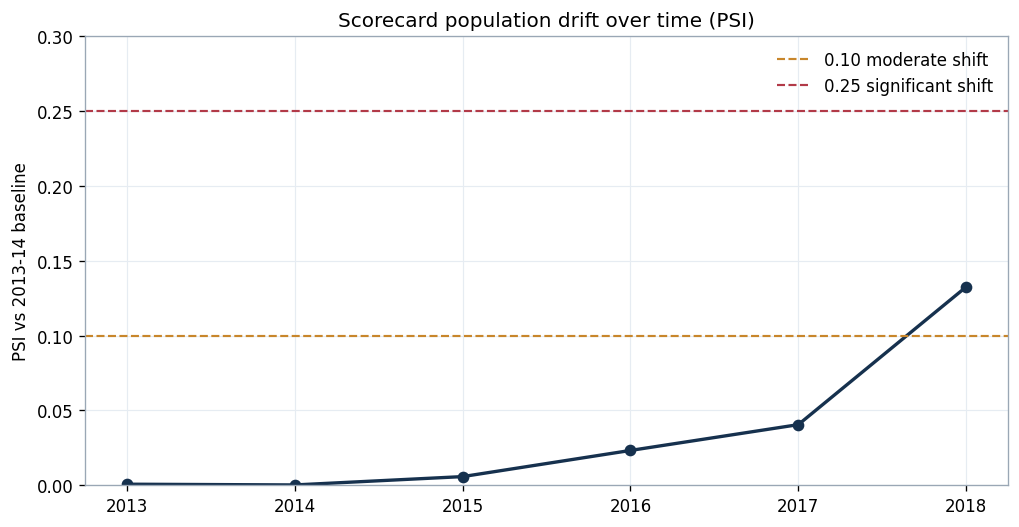

In [18]:
from IPython.display import Image
Image(filename="figures/04_psi_drift.png")

**Geographic concentration: top-10 states**

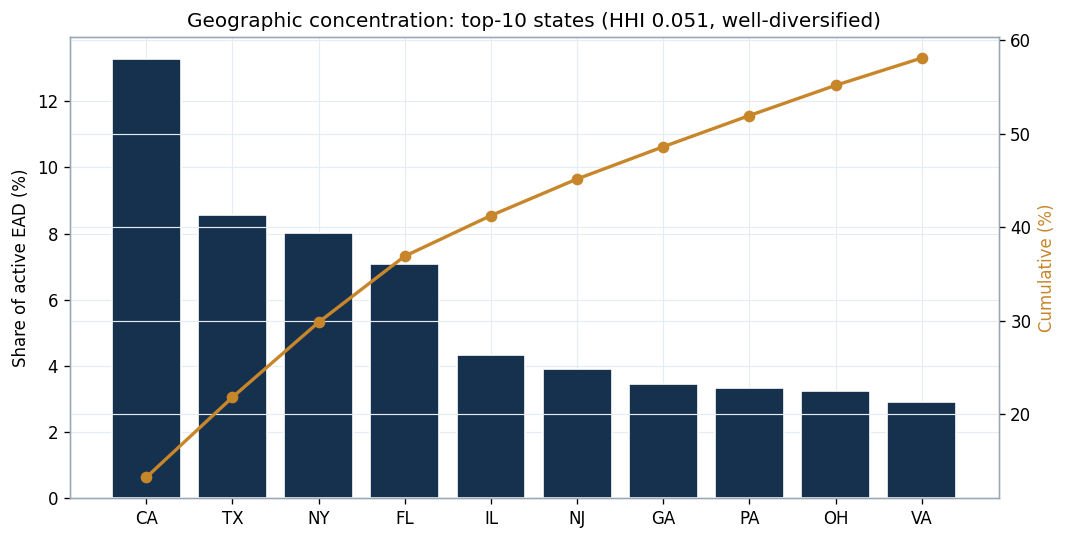

In [19]:
from IPython.display import Image
Image(filename="figures/05_concentration_state.png")

**Early-warning RAG dashboard**

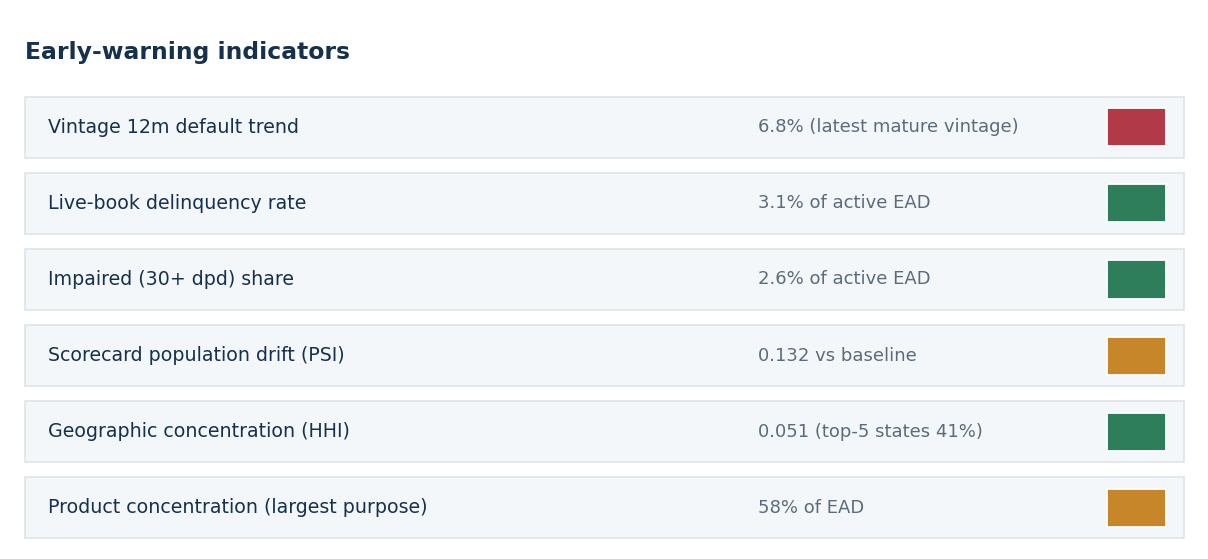

In [20]:
from IPython.display import Image
Image(filename="figures/06_ewi_dashboard.png")

**Default rate by risk band: early vs recent vintages**

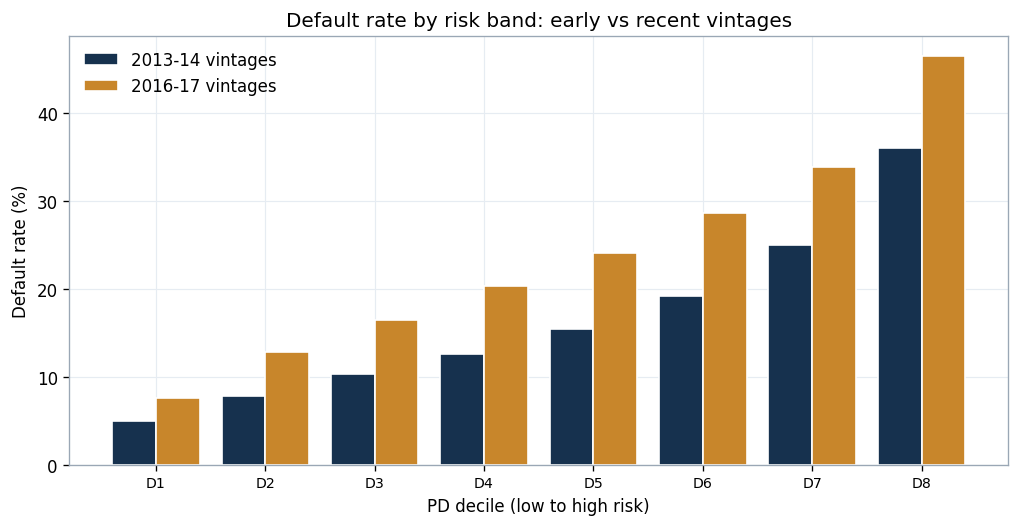

In [21]:
from IPython.display import Image
Image(filename="figures/07_band_trend.png")